<a href="https://colab.research.google.com/github/SOURAVNEAL/Brain-stroke-prediction1/blob/main/Stroke%202026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (5110, 11)
Missing values:
 bmi    201
dtype: int64
Target distribution (%):
 stroke
0    95.13
1     4.87
Name: proportion, dtype: float64
X_train: (4088, 10) | X_test: (1022, 10)
Train class counts: {0: 3889, 1: 199}
Test  class counts: {0: 972, 1: 50}

Majority-class baseline accuracy on test: 0.9511
Imputing...
   'bmi': 170 missing values imputed (spline).
Remaining NaNs  train: 0 | test: 0
After encoding  train: (4088, 25) | test: (1022, 25)
After scaling   train: (4088, 25) | test: (1022, 25)
After PCA       train: (4088, 16) | test: (1022, 16) (components=16, variance=0.9969)
Train shape fed to models: (4088, 16) (SMOTE is applied inside each CV fold)
XGBoost              best CV AUC = 0.8067 | {'smote__k_neighbors': 5, 'clf__subsample': 1.0, 'clf__reg_lambda': 1, 'clf__n_estimators': 500, 'clf__min_child_weight': 5, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__colsample_bytree': 0.6}
Random Forest        best CV AUC = 0.8153 | {'smote__k_neighbors': 7,

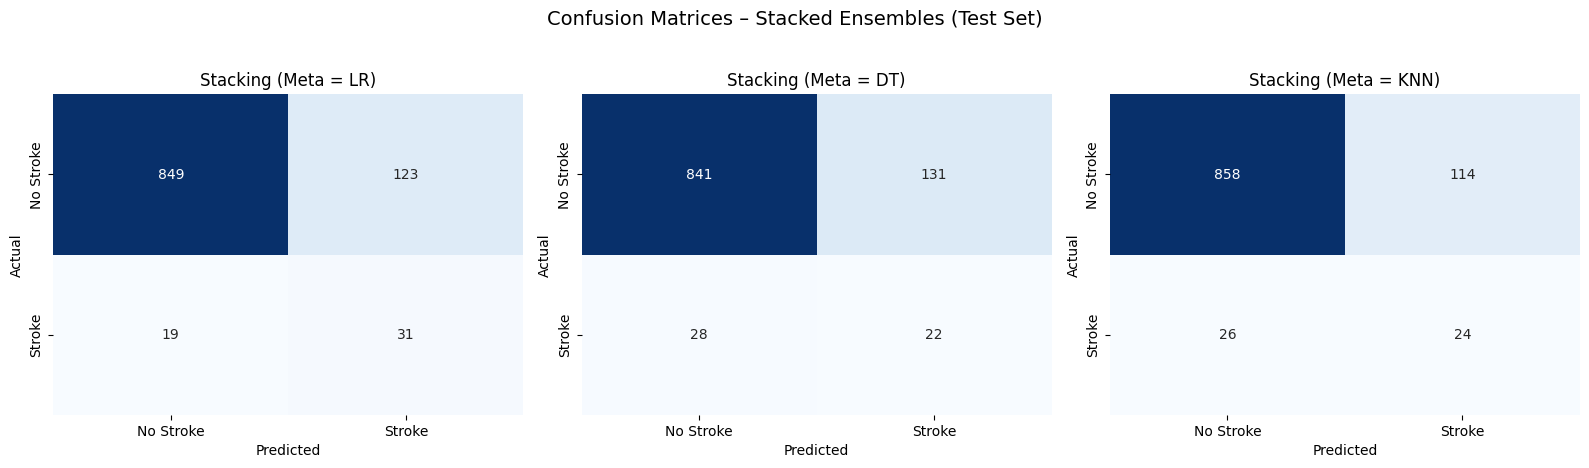

SUMMARY
Best individual: Logistic Regression    Acc=0.8806  AUC=0.8451  F1=0.3441  Recall=0.6400  Spec=0.8930
Best stacked   : Stacking (Meta = LR)   Acc=0.8611  AUC=0.8279  F1=0.3039  Recall=0.6200  Spec=0.8735

🏆 Best overall (AUC, F1 tie-break): Logistic Regression

Majority-class baseline accuracy: 0.9511
Targets: accuracy >= 0.96 -> not met | AUC >= 0.95 -> not met (best stacked: acc=0.8630, AUC=0.8279)

Notes:
 • Accuracy is capped near the baseline by class imbalance; an accuracy above the baseline with near-zero Sensitivity just means 'predict almost nobody'.
 • Thresholds were chosen on out-of-fold TRAIN predictions; the test set was used once.


In [6]:
# %% [markdown]
# # Stroke Prediction v2: Tuned Individual Classifiers vs. Stacked Ensembles
#
# **What changed vs. v1 (all leakage-free):**
# 1. **SMOTE moved inside the model pipelines.** Each base learner is
#    `SMOTE -> classifier`, so SMOTE is re-fitted inside every CV fold. In v1 SMOTE ran once
#    before the stacking CV, which let synthetic neighbours leak across inner folds.
#    The stacking meta-learner now trains on out-of-fold probabilities from *real* data.
# 2. **Hyper-parameter tuning** (RandomizedSearchCV / GridSearchCV, scoring = ROC-AUC, 5-fold
#    stratified CV on the training set only).
# 3. **Decision threshold chosen on out-of-fold TRAIN predictions** (never on the test set).
# 4. **Light feature engineering** (age², age×hypertension, age×heart disease, glucose×age).
# 5. PCA is kept (configurable). Extra metric: PR-AUC.
#
# Order: split -> spline impute -> features -> one-hot -> scale -> PCA -> tuned models.
# Everything is fitted on the training split only; the test set is only transformed.

# %%
# !pip install -q xgboost imbalanced-learn scipy    # uncomment if running in Colab

# %% [markdown]
# ## 0. Imports & configuration

# %%
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV, cross_val_predict
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, balanced_accuracy_score
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CSV_PATH = "/content/healthcare-dataset-stroke-data.csv"
TARGET = "stroke"

# ---- Tunable settings -------------------------------------------------------
USE_PCA = True                  # set False to skip PCA (usually helps tree models)
PCA_VARIANCE = 0.99             # variance to retain (spec asked for >= 0.95)
THRESHOLD_OBJECTIVE = "f1"      # "f1" | "balanced_accuracy" | "accuracy"
N_ITER_SEARCH = 15              # random-search iterations for XGB / RF
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# %% [markdown]
# ## 1. Data loading & basic cleaning

# %%
def load_and_clean(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df = df.replace("N/A", np.nan)
    df = df.drop(columns=["id"], errors="ignore")
    for col in ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", TARGET]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


df = load_and_clean(CSV_PATH)
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Target distribution (%):\n", (df[TARGET].value_counts(normalize=True) * 100).round(2))

# %% [markdown]
# ## 2. Stratified train / test split (80 / 20)

# %%
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train class counts:", y_train.value_counts().to_dict())
print("Test  class counts:", y_test.value_counts().to_dict())

BASE_NUM_COLS = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi"]
CAT_COLS = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

# Majority-class baseline: what "predict nobody has a stroke" scores on the test set
BASELINE_ACC = 1 - y_test.mean()
print(f"\nMajority-class baseline accuracy on test: {BASELINE_ACC:.4f}")

# %% [markdown]
# ## 3. Imputation (spline on train; train-median for test) + feature engineering

# %%
class TrainFittedImputer:
    """Spline imputation (train) with median / mode fallbacks; test uses train statistics."""

    def __init__(self, num_cols, cat_cols, order=3):
        self.num_cols, self.cat_cols, self.order = num_cols, cat_cols, order
        self.medians_, self.modes_, self.bounds_ = {}, {}, {}

    def _spline_fill(self, series):
        ordered = series.sort_index()
        positions = ordered.reset_index(drop=True)
        try:
            filled = positions.interpolate(method="spline", order=self.order,
                                           limit_direction="both")
        except Exception as exc:
            print(f"   spline failed for '{series.name}' ({exc}); using median.")
            filled = positions.copy()
        lo, hi = self.bounds_[series.name]
        filled = filled.clip(lo, hi).fillna(self.medians_[series.name])
        filled.index = ordered.index
        return filled.reindex(series.index)

    def fit_transform_train(self, X_tr):
        X_tr = X_tr.copy()
        for col in self.num_cols:
            observed = X_tr[col].dropna()
            self.medians_[col] = observed.median()
            self.bounds_[col] = (observed.min(), observed.max())
            if X_tr[col].isna().any():
                n = int(X_tr[col].isna().sum())
                X_tr[col] = self._spline_fill(X_tr[col])
                print(f"   '{col}': {n} missing values imputed (spline).")
        for col in self.cat_cols:
            self.modes_[col] = X_tr[col].mode().iloc[0]
            X_tr[col] = X_tr[col].fillna(self.modes_[col])
        return X_tr

    def transform(self, X_new):
        X_new = X_new.copy()
        for col in self.num_cols:
            X_new[col] = X_new[col].fillna(self.medians_[col])
        for col in self.cat_cols:
            X_new[col] = X_new[col].fillna(self.modes_[col])
        return X_new


def add_features(d: pd.DataFrame) -> pd.DataFrame:
    """Simple interaction features (computed row-wise, so no leakage)."""
    d = d.copy()
    d["age_sq"] = d["age"] ** 2
    d["age_x_hyper"] = d["age"] * d["hypertension"]
    d["age_x_heart"] = d["age"] * d["heart_disease"]
    d["glucose_x_age"] = d["avg_glucose_level"] * d["age"]
    return d


NUM_COLS = BASE_NUM_COLS + ["age_sq", "age_x_hyper", "age_x_heart", "glucose_x_age"]

print("Imputing...")
imputer = TrainFittedImputer(BASE_NUM_COLS, CAT_COLS, order=3)
X_train_imp = add_features(imputer.fit_transform_train(X_train))
X_test_imp = add_features(imputer.transform(X_test))
print("Remaining NaNs  train:", int(X_train_imp.isna().sum().sum()),
      "| test:", int(X_test_imp.isna().sum().sum()))

# %% [markdown]
# ## 4. Encoding -> scaling -> PCA (all fitted on the training split only)

# %%
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train_imp[CAT_COLS])


def encode(X_imp):
    cat = pd.DataFrame(ohe.transform(X_imp[CAT_COLS]),
                       columns=ohe.get_feature_names_out(CAT_COLS), index=X_imp.index)
    return pd.concat([X_imp[NUM_COLS], cat], axis=1)


X_train_enc, X_test_enc = encode(X_train_imp), encode(X_test_imp)
print("After encoding  train:", X_train_enc.shape, "| test:", X_test_enc.shape)

scaler = StandardScaler().fit(X_train_enc)
X_train_sc, X_test_sc = scaler.transform(X_train_enc), scaler.transform(X_test_enc)
print("After scaling   train:", X_train_sc.shape, "| test:", X_test_sc.shape)

if USE_PCA:
    pca = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE).fit(X_train_sc)
    X_train_p, X_test_p = pca.transform(X_train_sc), pca.transform(X_test_sc)
    print(f"After PCA       train: {X_train_p.shape} | test: {X_test_p.shape} "
          f"(components={pca.n_components_}, variance={pca.explained_variance_ratio_.sum():.4f})")
else:
    X_train_p, X_test_p = X_train_sc, X_test_sc
    print("PCA skipped.")

y_train_arr, y_test_arr = y_train.values, y_test.values
print("Train shape fed to models:", X_train_p.shape, "(SMOTE is applied inside each CV fold)")

# %% [markdown]
# ## 5. Tuned individual classifiers (SMOTE inside the pipeline)

# %%
def smote_pipe(clf):
    return ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)), ("clf", clf)])


def tune(pipe, params, search="random", n_iter=N_ITER_SEARCH, name=""):
    if search == "random":
        s = RandomizedSearchCV(pipe, params, n_iter=n_iter, scoring="roc_auc", cv=CV,
                               random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    else:
        s = GridSearchCV(pipe, params, scoring="roc_auc", cv=CV, n_jobs=-1, refit=True)
    s.fit(X_train_p, y_train_arr)
    print(f"{name:<20} best CV AUC = {s.best_score_:.4f} | {s.best_params_}")
    return s.best_estimator_


best = {}
best["XGBoost"] = tune(
    smote_pipe(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
    {"smote__k_neighbors": [3, 5, 7],
     "clf__n_estimators": [200, 300, 500],
     "clf__max_depth": [2, 3, 4, 5],
     "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
     "clf__subsample": [0.7, 0.85, 1.0],
     "clf__colsample_bytree": [0.6, 0.8, 1.0],
     "clf__min_child_weight": [1, 3, 5],
     "clf__reg_lambda": [1, 5, 10]},
    name="XGBoost")

best["Random Forest"] = tune(
    smote_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    {"smote__k_neighbors": [3, 5, 7],
     "clf__n_estimators": [200, 400],
     "clf__max_depth": [4, 6, 8, 12, None],
     "clf__min_samples_leaf": [1, 3, 5, 10],
     "clf__max_features": ["sqrt", "log2", 0.5]},
    name="Random Forest")

best["Logistic Regression"] = tune(
    smote_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    {"clf__C": [0.01, 0.1, 1, 10, 100]}, search="grid", name="Logistic Regression")

best["KNN"] = tune(
    smote_pipe(KNeighborsClassifier()),
    {"clf__n_neighbors": [5, 11, 21, 31, 51], "clf__weights": ["uniform", "distance"]},
    search="grid", name="KNN")

best["Decision Tree"] = tune(
    smote_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {"clf__max_depth": [3, 4, 5, 6, 8], "clf__min_samples_leaf": [5, 10, 20, 40]},
    search="grid", name="Decision Tree")

# %% [markdown]
# ## 6. Stacked ensembles (base = tuned XGBoost + tuned Random Forest)
# The base learners are the SMOTE pipelines above, so SMOTE happens inside every inner fold.
# Meta-learners receive out-of-fold probabilities from real (non-synthetic) samples.

# %%
def make_stacking(meta):
    return StackingClassifier(
        estimators=[("xgb", clone(best["XGBoost"])), ("rf", clone(best["Random Forest"]))],
        final_estimator=meta, cv=CV, stack_method="predict_proba", n_jobs=1)


stacked = {
    "Stacking (Meta = LR)": make_stacking(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Stacking (Meta = DT)": make_stacking(DecisionTreeClassifier(max_depth=3, min_samples_leaf=25,
                                                                 random_state=RANDOM_STATE)),
    "Stacking (Meta = KNN)": make_stacking(KNeighborsClassifier(n_neighbors=31)),
}

all_models = {**{k: clone(v) for k, v in best.items()}, **stacked}

# %% [markdown]
# ## 7. Threshold selection (out-of-fold TRAIN predictions) & test evaluation

# %%
def pick_threshold(y_true, prob, objective):
    grid = np.linspace(0.01, 0.99, 99)
    scorers = {
        "f1": lambda p: f1_score(y_true, p, zero_division=0),
        "balanced_accuracy": lambda p: balanced_accuracy_score(y_true, p),
        "accuracy": lambda p: accuracy_score(y_true, p),
    }
    scores = [scorers[objective]((prob >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(scores))])


def metrics_at(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Threshold": thr,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Sensitivity (Recall)": recall_score(y_true, pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "F1-Score": f1_score(y_true, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "_cm": np.array([[tn, fp], [fn, tp]]),
    }


rows, rows_acc, confusion_mats = [], [], {}

for name, model in all_models.items():
    print(f"Evaluating: {name} ...")
    # 1) out-of-fold probabilities on TRAIN -> choose thresholds (no test data involved)
    oof = cross_val_predict(clone(model), X_train_p, y_train_arr, cv=CV,
                            method="predict_proba", n_jobs=-1)[:, 1]
    thr = pick_threshold(y_train_arr, oof, THRESHOLD_OBJECTIVE)
    thr_acc = pick_threshold(y_train_arr, oof, "accuracy")

    # 2) final fit on full train, score the untouched test set
    model.fit(X_train_p, y_train_arr)
    prob = model.predict_proba(X_test_p)[:, 1]

    m = metrics_at(y_test_arr, prob, thr)
    confusion_mats[name] = m.pop("_cm")
    rows.append({"Model": name, **m})
    rows_acc.append({"Model": name, **{k: v for k, v in metrics_at(y_test_arr, prob, thr_acc).items()
                                       if k != "_cm"}})
    print(f"   thr={thr:.2f} | Acc={m['Accuracy']:.4f} | AUC={m['AUC-ROC']:.4f} "
          f"| F1={m['F1-Score']:.4f} | Recall={m['Sensitivity (Recall)']:.4f}")

# %% [markdown]
# ## 8. Full comparison table

# %%
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)

results_df = (pd.DataFrame(rows).sort_values(["AUC-ROC", "F1-Score"], ascending=False)
              .reset_index(drop=True))
results_df.index += 1
print(f"Threshold objective on train OOF predictions: '{THRESHOLD_OBJECTIVE}'\n")
print(results_df.round(4).to_string())
results_df.to_csv("stroke_model_comparison_v2.csv", index_label="Rank")

print("\n--- Same models, threshold chosen to maximise ACCURACY (for reference) ---")
acc_df = (pd.DataFrame(rows_acc).sort_values("Accuracy", ascending=False).reset_index(drop=True))
print(acc_df.round(4).to_string())

# %% [markdown]
# ## 9. Confusion matrices – stacked ensembles (test set)

# %%
stack_names = list(stacked.keys())
class_names = ["No Stroke", "Stroke"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, stack_names):
    sns.heatmap(confusion_mats[name], annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle("Confusion Matrices – Stacked Ensembles (Test Set)", y=1.03, fontsize=14)
plt.tight_layout()
plt.savefig("stacking_confusion_matrices_v2.png", dpi=200, bbox_inches="tight")
plt.show()

# %% [markdown]
# ## 10. Summary

# %%
individual_names = list(best.keys())
ind_df = results_df[results_df["Model"].isin(individual_names)]
stk_df = results_df[results_df["Model"].isin(stack_names)]
best_ind, best_stk, best_overall = ind_df.iloc[0], stk_df.iloc[0], results_df.iloc[0]

print("=" * 80)
print("SUMMARY")
print("=" * 80)
for label, r in [("Best individual", best_ind), ("Best stacked   ", best_stk)]:
    print(f"{label}: {r['Model']:<22} Acc={r['Accuracy']:.4f}  AUC={r['AUC-ROC']:.4f}  "
          f"F1={r['F1-Score']:.4f}  Recall={r['Sensitivity (Recall)']:.4f}  "
          f"Spec={r['Specificity']:.4f}")
print(f"\n🏆 Best overall (AUC, F1 tie-break): {best_overall['Model']}")

print(f"\nMajority-class baseline accuracy: {BASELINE_ACC:.4f}")
print(f"Targets: accuracy >= 0.96 -> {'MET' if (stk_df['Accuracy'] >= 0.96).any() else 'not met'}"
      f" | AUC >= 0.95 -> {'MET' if (stk_df['AUC-ROC'] >= 0.95).any() else 'not met'} "
      f"(best stacked: acc={stk_df['Accuracy'].max():.4f}, AUC={stk_df['AUC-ROC'].max():.4f})")
print("\nNotes:")
print(" • Accuracy is capped near the baseline by class imbalance; an accuracy above the "
      "baseline with near-zero Sensitivity just means 'predict almost nobody'.")
print(" • Thresholds were chosen on out-of-fold TRAIN predictions; the test set was used once.")